# Week 2 — The model is just a rule you can read

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Harjotsingh0311/flyrank-ml-internship/blob/main/notebooks/02_your_first_readable_model.ipynb?flush_cache=true)

You'll:
1. Write a **1-line hand rule** and rank pages with it.
2. Fit a **depth-2 decision tree** and `print` it — the model "learned" a readable if/else. Then compare — where does it beat your rule, and where doesn’t it?
3. See **why you never feed the outcome back in** — that's leakage.

The payoff isn't a high score. It's: *my intuition was rough, the model found the real signal, and I can read exactly what it found.*

## 0. Setup (Colab or local)
On Colab this clones the repo and installs requirements. Locally, select **Python 3.13 (FlyRank ML)** in VS Code. The setup locates the repository safely on Windows and checks that the active kernel and required packages are correct before loading the starter dataset.


In [1]:
import os
import sys
import subprocess
import importlib.util
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/flyrank-bih/flyrank-ml-internship-starter"
REPO_DIR = "flyrank-ml-internship-starter"
DATA_FILE = Path("data/raw/content_refresh_anonymized.csv")

if IN_COLAB:
    if not Path(REPO_DIR).is_dir() and not DATA_FILE.is_file():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, REPO_DIR], check=True)
    if not DATA_FILE.is_file():
        os.chdir(REPO_DIR)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
else:
    start = Path.cwd().resolve()
    root = next((p for p in (start, *start.parents)
                 if (p / DATA_FILE).is_file() and (p / "scripts/run_all.py").is_file()), None)
    if root is None:
        raise FileNotFoundError("Open the cloned FlyRank project folder in VS Code and restart the kernel.")
    os.chdir(root)

    if os.name == "nt":
        expected_python = root / ".venv" / "Scripts" / "python.exe"
    else:
        expected_python = root / ".venv" / "bin" / "python"

    if expected_python.is_file():
        # Check the environment prefix (not resolved interpreter symlinks).
        if Path(sys.prefix).resolve() != (root / ".venv").resolve():
            raise RuntimeError(
                f"Wrong notebook kernel: {sys.executable}\n"
                f"Select Python 3.13 (FlyRank ML) or {expected_python} "
                "in VS Code, restart the kernel, and run this cell again."
            )

    required = ("pandas", "numpy", "sklearn", "matplotlib", "reportlab", "duckdb", "huggingface_hub")
    missing = [name for name in required if importlib.util.find_spec(name) is None]
    if missing:
        raise ModuleNotFoundError(
            f"Missing packages in active kernel: {', '.join(missing)}\n"
            f'Run in the terminal: uv pip install --python "{sys.executable}" -r requirements.txt ipykernel\n'
            "Then restart the notebook kernel and run all cells."
        )

print("Python interpreter:", sys.executable)
print("Python version:", sys.version.split()[0])
print("Working dir:", os.getcwd())
assert DATA_FILE.is_file(), "Starter CSV not found."
print("Starter data found. You're ready.")


import pandas as pd
import numpy as np

df = pd.read_csv(DATA_FILE)
df["is_declining_label"] = df["trend_direction"].str.lower().eq("down").astype(int)
print(f"{len(df):,} pages | declining rate: {df['is_declining_label'].mean():.3f}")


Python interpreter: c:\workstation\3RD YEAR\flyrank-ml-internship-starter\.venv\Scripts\python.exe
Python version: 3.13.13
Working dir: C:\workstation\3RD YEAR\flyrank-ml-internship-starter
Starter data found. You're ready.
30,000 pages | declining rate: 0.542


## 1. A rule you write by hand: `stale x visible`
Intuition: a page worth reviewing is one that is **stale** (not updated in a while) **and** still **visible** (getting impressions). Rank those by how much exposure they have.

In [2]:
stale   = (df["days_since_last_update"] >= 180).astype(int)
visible = (df["impressions_90d"] >= 500).astype(int)
df["hand_rule_score"] = stale * visible * df["impressions_90d"]

top10 = df.sort_values("hand_rule_score", ascending=False).head(10)
top10[["impressions_90d", "days_since_last_update", "avg_position", "ctr", "trend_direction"]]

,impressions_90d,days_since_last_update,avg_position,ctr,trend_direction
16751,61678,194,19.7,0.15,down
16514,59472,194,24.8,0.13,down
7021,25715,194,22.2,0.23,down
21268,13299,193,10.5,0.49,down
11489,7812,194,39.0,0.01,down
12045,7558,193,17.9,0.20,down
698,4590,194,31.0,0.00,down
5327,4556,194,16.4,0.33,down
26810,4429,194,25.3,0.38,down
20837,1697,193,15.8,0.12,down


We need a way to score any ranking. **Precision@K** = of the top K pages a ranking flags, what fraction are actually declining.

In [3]:
def precision_at_k(scores, labels, k):
    order = np.argsort(-np.asarray(scores))
    topk = np.asarray(labels)[order[:k]]
    return topk.mean()

y = df["is_declining_label"].values
for k in (20, 50):
    print(f"Hand rule  Precision@{k}: {precision_at_k(df['hand_rule_score'], y, k):.3f}")

Hand rule  Precision@20: 0.900
Hand rule  Precision@50: 0.680


## 2. Let a model learn the rule — then read it
A **depth-2 decision tree** can only ask 3 yes/no questions. That constraint is the point: whatever it learns, you can read.

We give it a few **pre-decision** signals — never product flags.

In [4]:
from sklearn.tree import DecisionTreeClassifier, export_text

features = ["content_age_days", "days_since_last_update", "impressions_90d",
            "avg_position", "ctr", "word_count"]
X = df[features].replace([np.inf, -np.inf], np.nan).fillna(0)

tree = DecisionTreeClassifier(max_depth=2, class_weight="balanced", random_state=42)
tree.fit(X, y)

print(export_text(tree, feature_names=features))

|--- impressions_90d <= 5.50
|   |--- avg_position <= 0.75
|   |   |--- class: 0
|   |--- avg_position >  0.75
|   |   |--- class: 0
|--- impressions_90d >  5.50
|   |--- content_age_days <= 312.50
|   |   |--- class: 1
|   |--- content_age_days >  312.50
|   |   |--- class: 0



That printout **is** the model — a human-readable if/else. Now rank pages by the tree's probability and score it the same way.

In [5]:
tree_score = tree.predict_proba(X)[:, 1]
for k in (20, 50):
    hr = precision_at_k(df["hand_rule_score"], y, k)
    tr = precision_at_k(tree_score, y, k)
    print(f"Precision@{k}:  hand rule {hr:.3f}   vs   tree {tr:.3f}")

Precision@20:  hand rule 0.900   vs   tree 0.800
Precision@50:  hand rule 0.680   vs   tree 0.740


Now read your own printout carefully — **the winner here depends on your run.** A depth-2 tree can only give four different scores (one per leaf), so the "top 50" is mostly one big block of tied pages, and different library versions break those ties differently. On some stacks the tree wins at Precision@50; on others the hand rule holds both. **Both results are real.** The stable lesson: a sharp human rule can be excellent at the very top of the list; a model's advantage — when it shows up — appears deeper, where simple rules run out of signal; and any comparison built on heavily tied scores is fragile. Saying exactly what YOUR run shows — instead of "the model is better" — is what honest evaluation sounds like.

## 3. Why you can't feed the outcome back in
Your label is `trend_direction == "down"`, and `trend_pct` is the exact percentage change that bucket is computed from — so it **is** the answer in disguise. Watch what happens if you feed it in as a feature:

In [6]:
X_leaky = df[features + ["trend_pct"]].replace([np.inf, -np.inf], np.nan).fillna(0)
leaky = DecisionTreeClassifier(max_depth=2, class_weight="balanced", random_state=42).fit(X_leaky, y)
print(f"'Leaky' tree Precision@50: {precision_at_k(leaky.predict_proba(X_leaky)[:,1], y, 50):.3f}  <- looks amazing")
print(export_text(leaky, feature_names=features + ["trend_pct"]))

'Leaky' tree Precision@50: 1.000  <- looks amazing
|--- trend_pct <= -20.05
|   |--- word_count <= 212.00
|   |   |--- class: 1
|   |--- word_count >  212.00
|   |   |--- class: 1
|--- trend_pct >  -20.05
|   |--- trend_pct <= -19.95
|   |   |--- class: 0
|   |--- trend_pct >  -19.95
|   |   |--- class: 0



The tree just split on `trend_pct` and nailed the label — because the label is **derived from** `trend_pct`. That's **leakage**: the feature is the answer in disguise, and it teaches you nothing.

That's also why the starter data ships **only observable signals** — the product's own decision flags (health scores, "needs CTR fix", and so on) aren't included, so you can't accidentally train on them. You build from what was knowable *before* the outcome.

> Rule of thumb: if a feature would only be known *because someone already made the decision you're predicting*, it leaks. Leave it out.

## 4. 🔧 Your turn
- Change `max_depth` to 3 or 4 — does Precision@50 improve? Can you still read the tree?
- Swap in different features (drop `impressions_90d`, add `engagement_rate`). What does the tree choose to split on first?
- **Important caveat:** we scored *in-sample* here for teaching. The real pipeline uses **client-holdout** validation (`scripts/03_train_model.py`) so a client's pages never appear in both train and test. Re-run your comparison with a train/test split and see if the gap holds.

Write your experiment below.

### Experiment — depth, feature choice and generalization

Compare depth 2, 3 and 4 trees, then swap impressions for engagement rate in a depth-2 tree. Use one fixed 80/20 client-level holdout for every model and the hand rule. Client IDs are only for grouping; neither the outcome nor its derived fields is included as a feature.

Report training and held-out Precision@50, held-out Precision@20, tree complexity and the first split. Tied scores are ranked using a reproducible random order independent of the labels. Report the number of pages tied at the top-50 boundary so small ranking differences are not overinterpreted. The holdout comparison is exploratory, not an independent final model-selection test.


Train: 23,837 pages | 25 clients
Test:  6,163 pages | 7 clients
Overlapping clients: 0
Test declining rate: 0.511

Client-holdout comparison (all metrics on the same split):
                      train_P@50  test_P@20  test_P@50  tied_at_50  leaves      first_split
method                                                                                     
Hand rule                   0.76       0.45       0.44        6163     NaN                -
Tree depth 2                0.62       0.50       0.58        2963     4.0  impressions_90d
Tree depth 3                0.66       0.55       0.58        2209     8.0  impressions_90d
Tree depth 4                0.68       0.60       0.56        1319    16.0  impressions_90d
Depth 2 + engagement        0.68       0.40       0.54        3123     4.0     avg_position


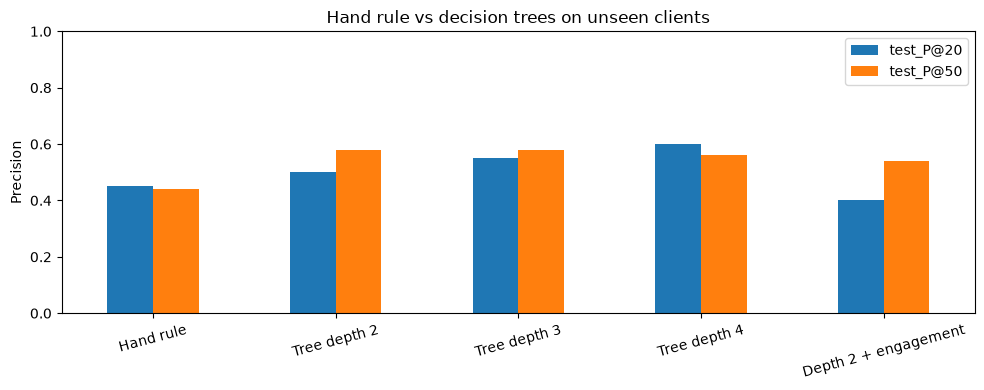


Readable depth-3 tree:
|--- impressions_90d <= 5.50
|   |--- avg_position <= 0.75
|   |   |--- impressions_90d <= 3.50
|   |   |   |--- class: 0
|   |   |--- impressions_90d >  3.50
|   |   |   |--- class: 0
|   |--- avg_position >  0.75
|   |   |--- content_age_days <= 108.50
|   |   |   |--- class: 0
|   |   |--- content_age_days >  108.50
|   |   |   |--- class: 0
|--- impressions_90d >  5.50
|   |--- content_age_days <= 312.50
|   |   |--- ctr <= 0.30
|   |   |   |--- class: 1
|   |   |--- ctr >  0.30
|   |   |   |--- class: 1
|   |--- content_age_days >  312.50
|   |   |--- avg_position <= 24.45
|   |   |   |--- class: 0
|   |   |--- avg_position >  24.45
|   |   |   |--- class: 0

Depth-2 tree after feature swap — first split: avg_position


In [7]:
# Your experiment: depth sweep + feature swap + client-level holdout
from sklearn.model_selection import GroupShuffleSplit
import matplotlib.pyplot as plt

groups = df["client_id"]
assert groups.notna().all(), "Missing client IDs — inspect before splitting."
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, test_idx = next(splitter.split(df, y, groups=groups))
assert not set(groups.iloc[train_idx]) & set(groups.iloc[test_idx]), "Client leakage!"
assert len(test_idx) >= 50 and len(train_idx) >= 50
assert len(np.unique(y[train_idx])) == 2, "Training split must contain both classes."

print(f"Train: {len(train_idx):,} pages | {groups.iloc[train_idx].nunique()} clients")
print(f"Test:  {len(test_idx):,} pages | {groups.iloc[test_idx].nunique()} clients")
print("Overlapping clients: 0")
print(f"Test declining rate: {y[test_idx].mean():.3f}")

# A fixed, label-independent tie-break shared by all methods.
def ranking_metrics(scores, labels, k, seed=42):
    scores = np.asarray(scores, dtype=float)
    labels = np.asarray(labels)
    tie_order = np.random.default_rng(seed).permutation(len(scores))
    order = np.lexsort((tie_order, -scores))
    boundary = scores[order[k - 1]]
    return float(labels[order[:k]].mean()), int(np.count_nonzero(scores == boundary))

def summarize(name, train_scores, test_scores, first_split="-", leaves=None):
    p20, _ = ranking_metrics(test_scores, y[test_idx], 20)
    p50, tied = ranking_metrics(test_scores, y[test_idx], 50)
    train_p50, _ = ranking_metrics(train_scores, y[train_idx], 50)
    return {
        "method": name, "train_P@50": train_p50, "test_P@20": p20,
        "test_P@50": p50, "tied_at_50": tied,
        "leaves": leaves, "first_split": first_split
    }

hand_scores = df["hand_rule_score"].fillna(0).to_numpy()
rows = [summarize("Hand rule", hand_scores[train_idx], hand_scores[test_idx])]
swap_features = [f for f in features if f != "impressions_90d"] + ["engagement_rate"]
configs = [(f"Tree depth {d}", d, features) for d in (2, 3, 4)]
configs.append(("Depth 2 + engagement", 2, swap_features))
fitted = {}

for name, depth, cols in configs:
    assert not {"trend_pct", "trend_direction", "is_declining_label", "client_id", "content_id"}.intersection(cols)
    inputs = df[cols].replace([np.inf, -np.inf], np.nan).fillna(0)
    model = DecisionTreeClassifier(max_depth=depth, class_weight="balanced", random_state=42)
    model.fit(inputs.iloc[train_idx], y[train_idx])
    root_index = model.tree_.feature[0]
    first_split = cols[root_index] if root_index >= 0 else "No split"
    rows.append(summarize(
        name,
        model.predict_proba(inputs.iloc[train_idx])[:, 1],
        model.predict_proba(inputs.iloc[test_idx])[:, 1],
        first_split, model.get_n_leaves()
    ))
    fitted[name] = (model, cols)

comparison = pd.DataFrame(rows).set_index("method")
print("\nClient-holdout comparison (all metrics on the same split):")
print(comparison.round(3).to_string())

ax = comparison[["test_P@20", "test_P@50"]].plot.bar(
    figsize=(10, 4), rot=15, ylim=(0, 1),
    title="Hand rule vs decision trees on unseen clients"
)
ax.set_ylabel("Precision")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

print("\nReadable depth-3 tree:")
model, cols = fitted["Tree depth 3"]
print(export_text(model, feature_names=cols))
print("Depth-2 tree after feature swap — first split:",
      comparison.loc["Depth 2 + engagement", "first_split"])


### Observations from this run

The next cell summarizes the measured comparison automatically. Read the output and check the printed tree before submitting. Precision@50 evaluates the ranking, not general classification accuracy; the experiment cannot establish causal refresh impact. A depth-4 tree may be less readable even if it improves ranking.

In [8]:
base = comparison.loc["Hand rule", "test_P@50"]
d2 = comparison.loc["Tree depth 2", "test_P@50"]
print(f"Hand rule held-out Precision@50: {base:.3f}")
print(f"Depth-2 held-out Precision@50: {d2:.3f}")

for name in ["Tree depth 3", "Tree depth 4", "Depth 2 + engagement"]:
    value = comparison.loc[name, "test_P@50"]
    delta = value - d2
    direction = "improved" if delta > 1e-9 else "decreased" if delta < -1e-9 else "was unchanged"
    print(f"{name}: {direction} vs depth 2 ({delta:+.3f}).")

best_score = comparison["test_P@50"].max()
best_names = comparison.index[np.isclose(comparison["test_P@50"], best_score)].tolist()
print(f"Highest observed held-out P@50: {best_score:.3f} ({', '.join(best_names)}).")
print("These are exploratory results on one unseen-client split.")
print("Large tie groups make top-K rankings sensitive to tie-breaking.")
print("The results support decision-support comparisons, not causal or future-traffic claims.")

Hand rule held-out Precision@50: 0.440
Depth-2 held-out Precision@50: 0.580
Tree depth 3: was unchanged vs depth 2 (+0.000).
Tree depth 4: decreased vs depth 2 (-0.020).
Depth 2 + engagement: decreased vs depth 2 (-0.040).
Highest observed held-out P@50: 0.580 (Tree depth 2, Tree depth 3).
These are exploratory results on one unseen-client split.
Large tie groups make top-K rankings sensitive to tie-breaking.
The results support decision-support comparisons, not causal or future-traffic claims.


### Save your work
**Colab:** *File → Save a copy in GitHub* (your submission) and *File → Save a copy in Drive*.

You now have the two core reflexes of applied ML: **discover before you model**, and **prefer a model you can read and can't fool**. That's the whole foundation the capstone builds on.

**VS Code:** run all cells with the project `.venv` kernel, save with `Ctrl+S`, and commit this notebook at `notebooks/02_your_first_readable_model.ipynb`. Keep the outputs visible on GitHub. Do not commit generated datasets or tokens.
